# Spectral Visualisation and Classification

This notebook covers the visualisation and binary classification of mean reflectance spectra from hyperspectral images. The input is a CSV file of MSC-corrected mean spectra (one row per sample) — for example the output of *1_hsi_processing*, though the two notebooks are fully independent.

Two sensors are analysed in parallel, **VNIR** and **SWIR**, using a shared set of functions. A cross-sensor comparison is provided at the end.

**Notebook structure**

| # | Section | Purpose |
|---|---------|---------|
| 1 | Setup | Imports and plotting style |
| 2 | Configuration | File paths for each sensor |
| 3 | Helper Functions | Reusable data loading and analysis functions |
| 4 | VNIR Analysis | Visualisation, statistics, ML for VNIR spectra |
| 5 | SWIR Analysis | Identical pipeline applied to SWIR spectra |
| 6 | Cross-Sensor Comparison | Performance table and side-by-side plots |

## 1. Setup & Requirements

In [1]:
from collections import Counter

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from scipy.signal import find_peaks
from statsmodels.stats.multitest import multipletests

from sklearn.ensemble import RandomForestClassifier
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import (GridSearchCV, GroupKFold,
                                     LeaveOneGroupOut)
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, confusion_matrix)

In [2]:
custom_params = {
    "axes.spines.right": False,
    "axes.spines.top": False,
    "font.family": "arial",
    "figure.figsize": (5, 3),
    "figure.dpi": 150,
    "lines.linewidth": 1.5,
    "axes.linewidth": 1.0,
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",
    "savefig.dpi": 300,
}
sns.set_theme(style="ticks", context="paper", font_scale=1.5, rc=custom_params)
plt.rcParams.update(custom_params)
sns.set_palette("tab10")

## 2. Configuration

Set the path to each sensor's pre-computed MSC-corrected mean-spectra file.  
Each CSV must contain a `Fish` column (sample identifier), a `Treatment` column (binary class label), and one numerical column per wavelength (column name = wavelength in nm).

In [3]:
SENSORS = {
    "VNIR": "../output/spectra/vnir_mean_spectra_msc.csv",
    "SWIR": "../output/spectra/swir_mean_spectra_msc.csv",
}

## 3. Helper Functions

Three lightweight wrappers centralise the repetitive steps so the VNIR and SWIR analysis sections call the same code with different inputs.

In [4]:
def load_and_prepare(csv_file):
    """Load a mean-spectra CSV and return wide-form df and long-form df_spectra.

    Parameters
    ----------
    csv_file : str
        Path to a CSV with columns [Fish, Treatment, wl1, wl2, ...].

    Returns
    -------
    df : DataFrame  (wide — one row per sample)
    df_spectra : DataFrame  (long — one row per sample × wavelength)
    """
    df = pd.read_csv(csv_file, sep=";")
    df_spectra = df.melt(id_vars=["Fish", "Treatment"],
                         var_name="Wavelength", value_name="Intensity")
    df_spectra["Wavelength"] = df_spectra["Wavelength"].astype(float)
    df_spectra["Image"] = df_spectra["Fish"].astype(str) + "-" + df_spectra["Treatment"]
    df_spectra = df_spectra.sort_values(by=["Fish", "Treatment"]).reset_index(drop=True)
    return df, df_spectra


def prepare_ml_data(df):
    """Extract X, y, groups and wavelength list from a wide-form spectra DataFrame.

    Parameters
    ----------
    df : DataFrame
        Wide-form with columns [Fish, Treatment, wl1, wl2, ...].

    Returns
    -------
    X : ndarray (n_samples, n_features)
    y : ndarray (n_samples,)  — 0 = class 0, 1 = class 1
    groups : ndarray  — sample IDs
    wavelengths : list of float
    """
    groups = df["Fish"].values
    df_ml = df.drop(columns=["Fish"]).copy()
    df_ml["Treatment"] = df_ml["Treatment"].map({"C": 0, "K": 1})
    X = df_ml.drop(columns=["Treatment"]).values
    y = df_ml["Treatment"].values
    wavelengths = df_ml.drop(columns=["Treatment"]).columns.astype(float).tolist()
    return X, y, groups, wavelengths


def run_ttest_analysis(df_spectra):
    """Welch t-test + Benjamini-Hochberg FDR correction + Cohen's d at every wavelength.

    Parameters
    ----------
    df_spectra : DataFrame
        Long-form with columns [Wavelength, Treatment, Intensity].

    Returns
    -------
    results_df : DataFrame
        Columns: Wavelength, t_stat, p_value, cohens_d, mean_intensity,
                 p_adjusted, Significant.
    """
    records = []
    for wl in df_spectra["Wavelength"].unique():
        subset = df_spectra[df_spectra["Wavelength"] == wl]
        c_vals = subset[subset["Treatment"] == "C"]["Intensity"].values
        k_vals = subset[subset["Treatment"] == "K"]["Intensity"].values
        t_stat, p_value = ttest_ind(c_vals, k_vals, equal_var=False)
        n_c, n_k = len(c_vals), len(k_vals)
        pooled_std = np.sqrt(((n_c - 1) * np.var(c_vals, ddof=1)
                              + (n_k - 1) * np.var(k_vals, ddof=1))
                             / (n_c + n_k - 2))
        cohens_d = ((np.mean(c_vals) - np.mean(k_vals)) / pooled_std
                    if pooled_std > 0 else 0.0)
        records.append({
            "Wavelength": wl, "t_stat": t_stat, "p_value": p_value,
            "cohens_d": cohens_d,
            "mean_intensity": np.mean(np.concatenate([c_vals, k_vals])),
        })
    res_df = pd.DataFrame(records)
    reject, p_adjusted, _, _ = multipletests(res_df["p_value"], alpha=0.05, method="fdr_bh")
    res_df["p_adjusted"] = p_adjusted
    res_df["Significant"] = reject
    return res_df

## 4. VNIR Analysis

### 4.1 Data Loading

In [5]:
df, df_spectra = load_and_prepare(SENSORS["VNIR"])
print(f"VNIR — {df['Fish'].nunique()} samples, "
      f"{len(df.columns) - 2} wavelengths, "
      f"{df['Treatment'].nunique()} classes")
df_spectra.head()

VNIR — 24 samples, 224 wavelengths, 2 classes


,Fish,Treatment,Wavelength,Intensity,Image
0,1,C,397.66,0.200511,1-C
1,1,C,400.28,0.195683,1-C
2,1,C,402.90,0.185905,1-C
3,1,C,405.52,0.176405,1-C
4,1,C,408.13,0.167391,1-C


### 4.2 Visualisation

#### All Samples

C:\Users\lalle\AppData\Local\Temp\ipykernel_22968\2056714792.py:2: UserWarning: 
The palette list has fewer values (10) than needed (48) and will cycle, which may produce an uninterpretable plot.
  sns.lineplot(


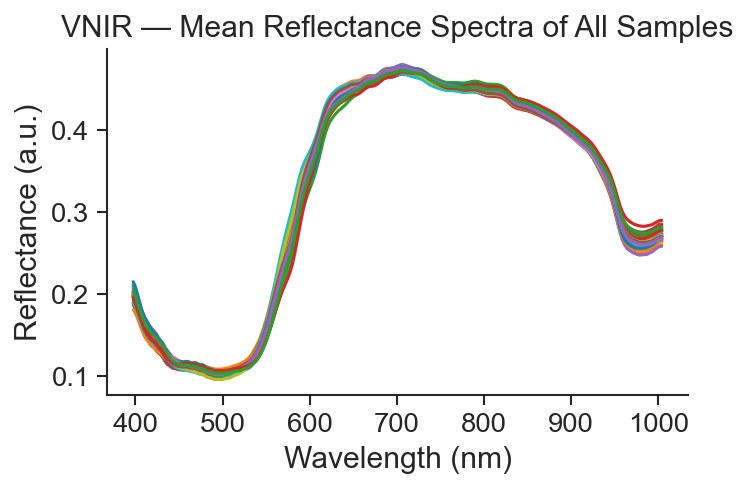

In [6]:
n_images = df_spectra["Image"].nunique()
sns.lineplot(
    data=df_spectra, x="Wavelength", y="Intensity",
    hue="Image", units="Image",
    estimator=None, palette=sns.color_palette("tab10")[::-1],
    legend=False, errorbar=None,
)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Reflectance (a.u.)")
plt.title("VNIR — Mean Reflectance Spectra of All Samples")
plt.show()

#### Mean Spectral Reflectance per Treatment

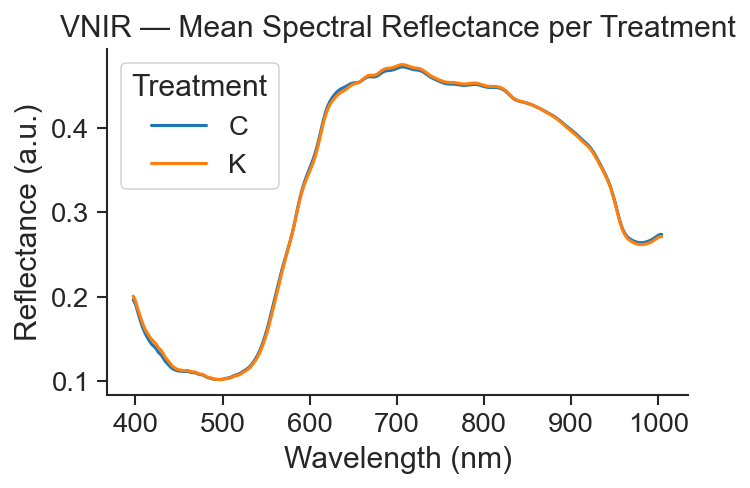

In [7]:
sns.lineplot(
    data=df_spectra, x="Wavelength", y="Intensity",
    hue="Treatment", errorbar=None,
)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Reflectance (a.u.)")
plt.title("VNIR — Mean Spectral Reflectance per Treatment")
plt.legend(title="Treatment")
plt.show()

#### Adjusted Mean Spectral Reflectance

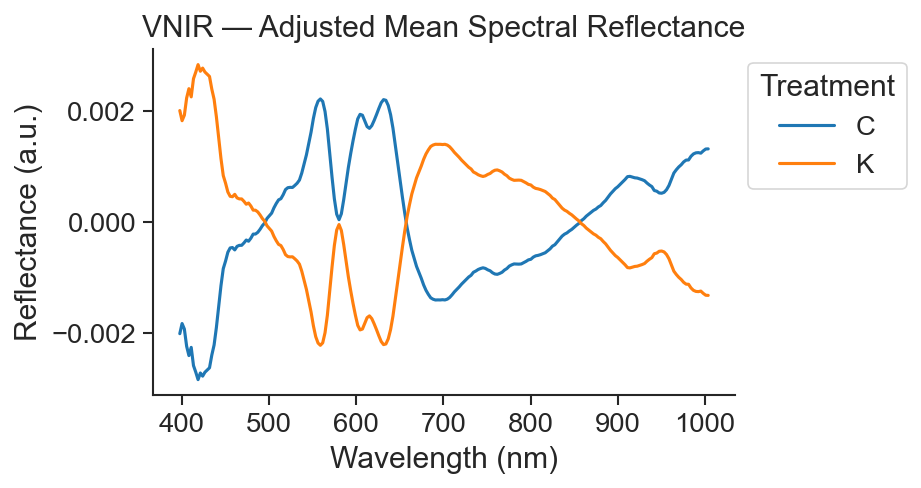

In [8]:
df_C_mean = (df_spectra[df_spectra["Treatment"] == "C"]
             .groupby("Wavelength")["Intensity"].mean().reset_index())
df_K_mean = (df_spectra[df_spectra["Treatment"] == "K"]
             .groupby("Wavelength")["Intensity"].mean().reset_index())

grand_mean = (df_C_mean["Intensity"] + df_K_mean["Intensity"]) / 2
df_C_mean["Adjusted"] = df_C_mean["Intensity"] - grand_mean
df_K_mean["Adjusted"] = df_K_mean["Intensity"] - grand_mean

sns.lineplot(data=df_C_mean, x="Wavelength", y="Adjusted", label="C", errorbar=None)
sns.lineplot(data=df_K_mean, x="Wavelength", y="Adjusted", label="K", errorbar=None)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Reflectance (a.u.)")
plt.title("VNIR — Adjusted Mean Spectral Reflectance")
plt.legend(title="Treatment", bbox_to_anchor=(1, 1), loc="upper left")
plt.show()

### 4.3 Statistical Analysis

Welch's t-test (unequal-variance) is applied independently at each wavelength to test whether the two treatments differ. Benjamini-Hochberg FDR correction controls the false discovery rate across all simultaneous tests. Cohen's *d* is reported as a standardised effect size per wavelength. Wavelengths with FDR-adjusted *p* < 0.05 are highlighted on the mean spectrum.

In [9]:
results_df = run_ttest_analysis(df_spectra)

n_sig = results_df["Significant"].sum()
n_total = len(results_df)
print(f"VNIR — Significant wavelengths (FDR-adjusted p < 0.05): {n_sig} / {n_total}")
print(f"Cohen's d range: [{results_df['cohens_d'].min():.3f}, {results_df['cohens_d'].max():.3f}]")

VNIR — Significant wavelengths (FDR-adjusted p < 0.05): 60 / 224
Cohen's d range: [-1.381, 0.844]


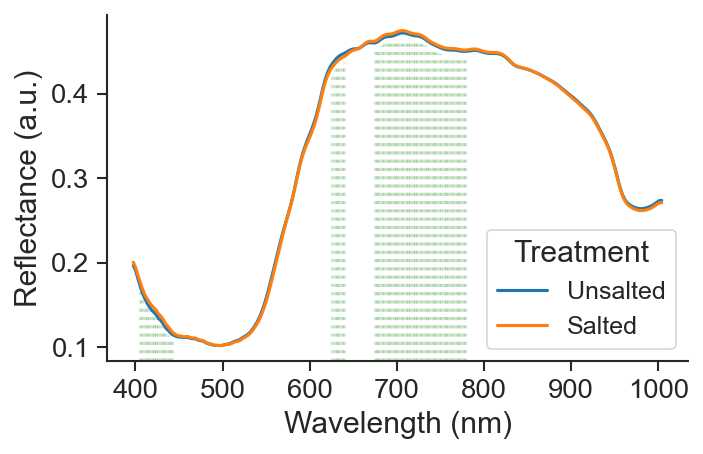

In [41]:
sns.lineplot(
    data=df_spectra, x="Wavelength", y="Intensity",
    hue="Treatment", estimator=np.mean, errorbar=None,
)
y_min, y_max = plt.ylim()
for _, row in results_df[results_df["Significant"]].iterrows():
    wl = row["Wavelength"]
    intensity = row["mean_intensity"]
    ymax_rel = (intensity - y_min) / (y_max - y_min)
    plt.axvline(x=wl, color="green", linestyle=":", alpha=0.2, ymax=ymax_rel - 0.02)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Reflectance (a.u.)")
# plt.title("VNIR — Significant Wavelengths (FDR-corrected)")
plt.legend(title="Treatment", labels=["Unsalted", "Salted"], fontsize=12)
plt.show()

### 4.4 Machine Learning Classification

Two classifiers are evaluated with Leave-One-Group-Out (LOGO) cross-validation, where each fish acts as a held-out group for one fold.

- **PLS-DA** — the optimal number of components is selected by inner GroupKFold CV on the training portion of each LOGO fold; the mode across folds is used to refit the final model on all data.
- **Random Forest** — optional GridSearchCV tunes `n_estimators` and `min_samples_split` within the same grouped CV structure.

In [11]:
def calculate_vip(pls_model, X):
    """Variable Importance in Projection (VIP) scores for a fitted PLSRegression."""
    t = pls_model.x_scores_
    w = pls_model.x_weights_
    q = pls_model.y_loadings_
    _, p = X.shape
    s = np.sum(t**2, axis=0) * (q**2).ravel()
    total_s = np.sum(s)
    vip = np.zeros(p)
    for i in range(p):
        vip[i] = np.sqrt(p * np.sum(s * (w[i, :] ** 2)) / total_s)
    return vip


def pls_da_classification(X, y, groups, max_components=10, cv=5,
                          scoring="accuracy"):
    """PLS-DA with Leave-One-Group-Out cross-validation."""
    logo = LeaveOneGroupOut()
    groups = np.asarray(groups)

    y_true_all, y_pred_all, y_scores_all = [], [], []
    all_n_components = []
    acc_cv_scores = np.zeros(max_components)

    for train_idx, test_idx in logo.split(X, y, groups):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]
        train_groups = groups[train_idx]

        gkf = GroupKFold(n_splits=cv)
        best_score, best_n = -np.inf, 1

        for n in range(1, max_components + 1):
            pls = PLSRegression(n_components=n)
            fold_scores = []
            for tr, va in gkf.split(X_train, y_train, train_groups):
                pls.fit(X_train[tr], y_train[tr])
                pred = pls.predict(X_train[va]).ravel()
                if scoring == "accuracy":
                    fold_scores.append(
                        accuracy_score(y_train[va], (pred > 0.5).astype(int))
                    )
                elif scoring == "roc_auc":
                    fold_scores.append(roc_auc_score(y_train[va], pred))
                else:
                    raise ValueError(f"Unsupported scoring: {scoring}")
            ms = np.mean(fold_scores)
            acc_cv_scores[n - 1] += ms
            if ms > best_score:
                best_score, best_n = ms, n

        model = PLSRegression(n_components=best_n).fit(X_train, y_train)
        y_pred_scores = model.predict(X_test).ravel()
        y_pred_class = (y_pred_scores > 0.5).astype(int)

        y_true_all.extend(y_test)
        y_pred_all.extend(y_pred_class)
        y_scores_all.extend(y_pred_scores)
        all_n_components.append(best_n)

    y_true_all = np.array(y_true_all)
    y_pred_all = np.array(y_pred_all)
    y_scores_all = np.array(y_scores_all)

    n_folds = logo.get_n_splits(X, y, groups)
    mean_cv_scores = acc_cv_scores / n_folds

    metrics = {
        "accuracy":  accuracy_score(y_true_all, y_pred_all),
        "auc":       roc_auc_score(y_true_all, y_scores_all),
        "precision": precision_score(y_true_all, y_pred_all, zero_division=0),
        "recall":    recall_score(y_true_all, y_pred_all, zero_division=0),
        "f1":        f1_score(y_true_all, y_pred_all, zero_division=0),
    }

    final_n = Counter(all_n_components).most_common(1)[0][0]
    final_model = PLSRegression(n_components=final_n).fit(X, y)
    vip = calculate_vip(final_model, X)

    print(f"--- PLS-DA Leave-One-Group-Out CV ({n_folds} folds) ---")
    print(f"n_components (mode): {final_n}  "
          f"(distribution: {dict(Counter(all_n_components))})")
    for k, v in metrics.items():
        print(f"  {k}: {v:.4f}")

    return {
        "model": final_model,
        "vip": vip,
        "metrics": metrics,
        "n_components": final_n,
        "target": {"y_pred": y_pred_all, "y_true": y_true_all},
        "mean_test_scores": list(mean_cv_scores),
    }


def random_forest_classification(X, y, groups, use_grid_search=False):
    """Random Forest with Leave-One-Group-Out cross-validation."""
    logo = LeaveOneGroupOut()
    groups = np.asarray(groups)

    param_grid = {
        "n_estimators": [30, 50, 100, 200],
        "min_samples_split": [2, 5, 10],
    }

    y_true_all, y_pred_all, y_scores_all = [], [], []

    for train_idx, test_idx in logo.split(X, y, groups):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]
        train_groups = groups[train_idx]

        rf = RandomForestClassifier(random_state=42)
        if use_grid_search:
            gkf = GroupKFold(n_splits=5)
            grid = GridSearchCV(rf, param_grid, cv=gkf, scoring="accuracy",
                                n_jobs=-1, verbose=0)
            grid.fit(X_train, y_train, groups=train_groups)
            fitted_rf = grid.best_estimator_
        else:
            fitted_rf = rf.fit(X_train, y_train)

        y_pred = fitted_rf.predict(X_test)
        y_proba = fitted_rf.predict_proba(X_test)[:, 1]

        y_true_all.extend(y_test)
        y_pred_all.extend(y_pred)
        y_scores_all.extend(y_proba)

    y_true_all = np.array(y_true_all)
    y_pred_all = np.array(y_pred_all)
    y_scores_all = np.array(y_scores_all)

    metrics = {
        "accuracy":  accuracy_score(y_true_all, y_pred_all),
        "auc":       roc_auc_score(y_true_all, y_scores_all),
        "precision": precision_score(y_true_all, y_pred_all, zero_division=0),
        "recall":    recall_score(y_true_all, y_pred_all, zero_division=0),
        "f1":        f1_score(y_true_all, y_pred_all, zero_division=0),
    }

    n_folds = logo.get_n_splits(X, y, groups)
    final_rf = RandomForestClassifier(random_state=42)
    if use_grid_search:
        gkf = GroupKFold(n_splits=5)
        grid = GridSearchCV(final_rf, param_grid, cv=gkf, scoring="accuracy",
                            n_jobs=-1, verbose=0)
        grid.fit(X, y, groups=groups)
        final_rf = grid.best_estimator_
    else:
        final_rf.fit(X, y)

    print(f"--- Random Forest Leave-One-Group-Out CV ({n_folds} folds) ---")
    for k, v in metrics.items():
        print(f"  {k}: {v:.4f}")

    return final_rf, y_true_all, y_pred_all, metrics


def plot_confusion_matrix(y_true, y_pred, class_names, title="Confusion Matrix",
                          ax=None):
    """Plot a normalised confusion matrix."""
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]
    if ax is None:
        plt.figure(figsize=(3, 3))
        ax = plt.gca()
    sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    if ax is plt.gca():
        plt.show()


def find_local_maxima(df, th, prominence=0.0):
    """Find local maxima above threshold in a two-column DataFrame."""
    x_vals = df.iloc[:, 0].values
    scores = df.iloc[:, 1].values
    peaks, _ = find_peaks(scores, height=th, prominence=prominence)
    return [float(x_vals[i]) for i in peaks]

In [12]:
X, y, groups, wavelengths = prepare_ml_data(df)

# PLS-DA (Leave-One-Group-Out CV)
result = pls_da_classification(X, y, groups=groups, max_components=20, cv=5,
                               scoring="accuracy")

--- PLS-DA Leave-One-Group-Out CV (24 folds) ---
n_components (mode): 13  (distribution: {13: 8, 8: 1, 16: 4, 11: 2, 17: 1, 15: 1, 10: 3, 12: 2, 14: 1, 9: 1})
  accuracy: 0.9792
  auc: 1.0000
  precision: 0.9600
  recall: 1.0000
  f1: 0.9796


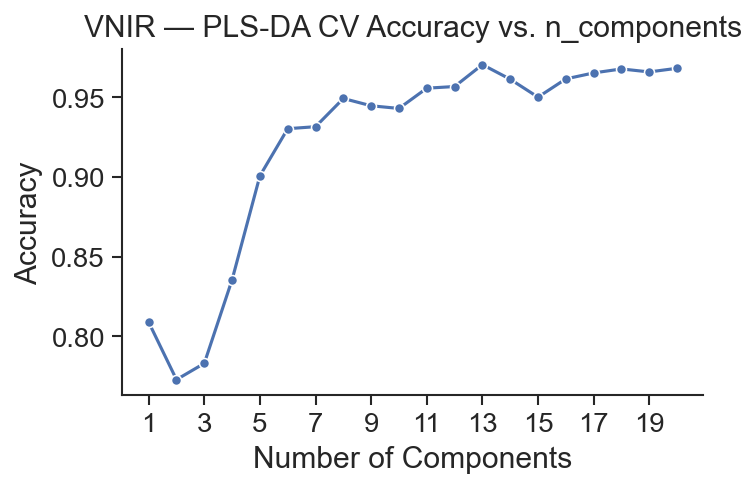

In [13]:
n_comp = len(result["mean_test_scores"])
sns.lineplot(
    x=range(1, n_comp + 1), y=result["mean_test_scores"],
    marker="o", linestyle="-", color="b",
)
plt.xlabel("Number of Components")
plt.xticks(np.arange(1, n_comp + 1, step=2))
plt.ylabel("Accuracy")
plt.title("VNIR — PLS-DA CV Accuracy vs. n_components")
plt.show()

In [14]:
# Random Forest (Leave-One-Group-Out CV)
rf, rf_y_test, rf_y_pred, rf_metrics = random_forest_classification(
    X, y, groups=groups, use_grid_search=True,
)

--- Random Forest Leave-One-Group-Out CV (24 folds) ---
  accuracy: 0.8125
  auc: 0.8802
  precision: 0.8261
  recall: 0.7917
  f1: 0.8085


### 4.5 Results & Interpretation

#### Feature Importance (Random Forest)

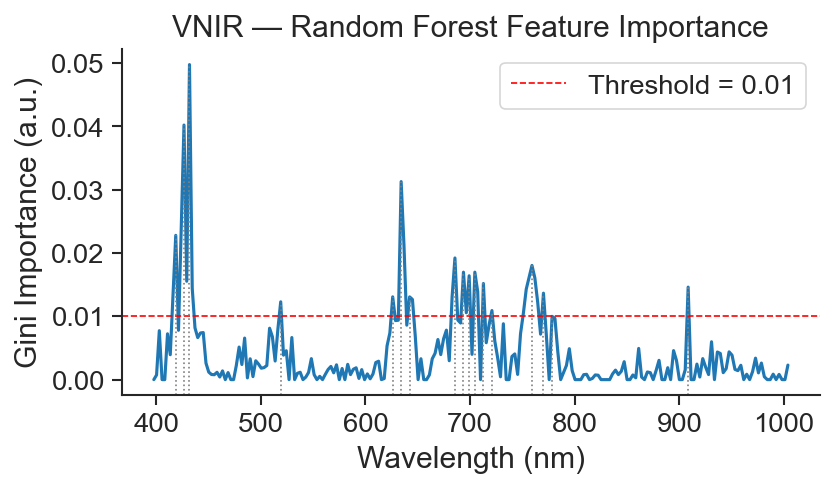

In [15]:
df_importance = pd.DataFrame({
    "Wavelength": wavelengths,
    "Importance": rf.feature_importances_,
})

plt.figure(figsize=(6, 3))
sns.lineplot(data=df_importance, x="Wavelength", y="Importance",
             estimator=None, errorbar=None)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Gini Importance (a.u.)")
y_min, y_max = plt.ylim()
plt.axhline(y=0.01, color="red", linestyle="--", label="Threshold = 0.01", lw=0.8)
biomarkers = find_local_maxima(df_importance, th=0.01)
for x in biomarkers:
    score = df_importance.loc[df_importance["Wavelength"] == x, "Importance"].iloc[0]
    ymax_rel = (score - y_min) / (y_max - y_min)
    plt.axvline(x=x, ymax=ymax_rel, color="gray", linestyle=":", lw=0.8)
plt.legend()
plt.title("VNIR — Random Forest Feature Importance")
plt.show()

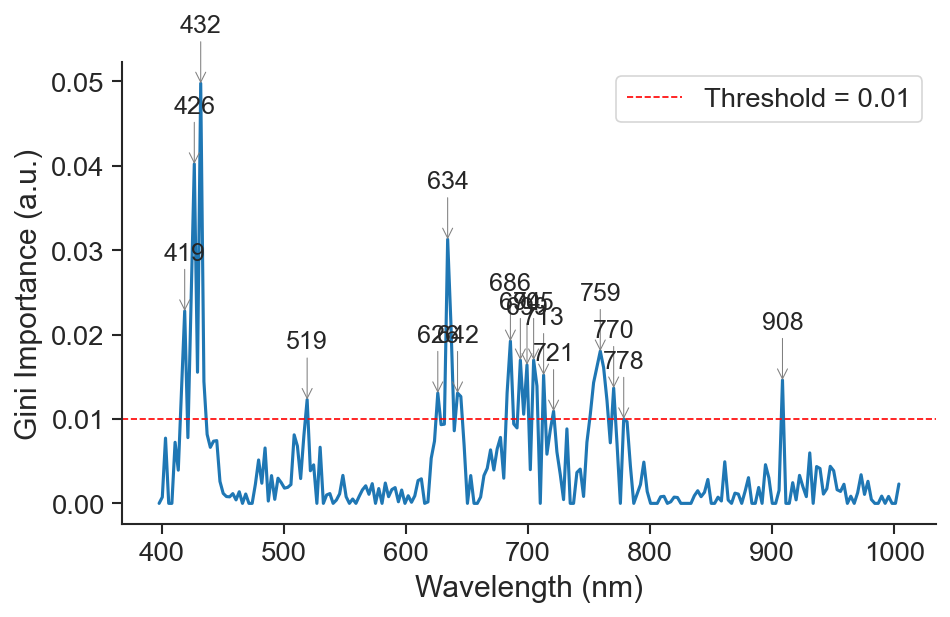

In [86]:
plt.figure(figsize=(7, 4))
sns.lineplot(data=df_importance, x="Wavelength", y="Importance",
             estimator=None, errorbar=None)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Gini Importance (a.u.)")
plt.axhline(y=0.01, color="red", linestyle="--", label="Threshold = 0.01", lw=0.8)
y_min, y_max = plt.ylim()
prev_x, offset = None, 0
for x in sorted(biomarkers):
    score = df_importance.loc[df_importance["Wavelength"] == x, "Importance"].iloc[0]
    if prev_x is not None and abs(x - prev_x) < 5:
        offset += 1
    else:
        offset = 0
    prev_x = x
    plt.annotate(
        f"{int(round(x))}", xy=(x, score),
        xytext=(x, score + (y_max - y_min) * 0.1 * (offset + 1)),
        ha="center", va="bottom", fontsize=12,
        arrowprops=dict(arrowstyle="->", color="gray", lw=0.5,
                        shrinkA=0, shrinkB=0),
    )
plt.legend()
plt.show()

#### VIP Scores (PLS-DA)

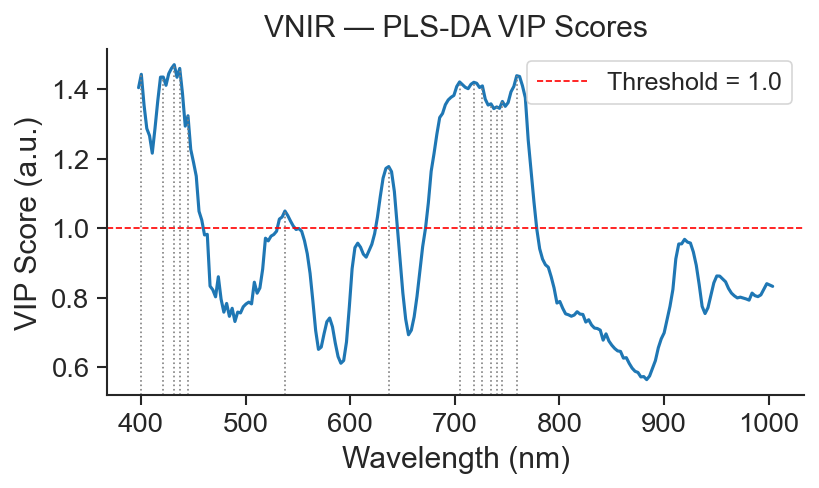

In [93]:
df_vip = pd.DataFrame({
    "Wavelength": wavelengths,
    "VIP Score": result["vip"],
})

plt.figure(figsize=(6, 3))
sns.lineplot(data=df_vip, x="Wavelength", y="VIP Score",
             estimator=None, errorbar=None)
plt.xlabel("Wavelength (nm)")
plt.ylabel("VIP Score (a.u.)")
plt.axhline(y=1.0, color="red", linestyle="--", label="Threshold = 1.0", lw=0.8)
vip_peaks = find_local_maxima(df_vip, th=1.0)
y_min, y_max = plt.ylim()
for x in vip_peaks:
    score = df_vip.loc[df_vip["Wavelength"] == x, "VIP Score"].iloc[0]
    ymax_rel = (score - y_min) / (y_max - y_min)
    plt.axvline(x=x, ymax=ymax_rel, color="gray", linestyle=":", lw=0.8)
plt.legend(fontsize=12)
plt.title("VNIR — PLS-DA VIP Scores")
plt.show()

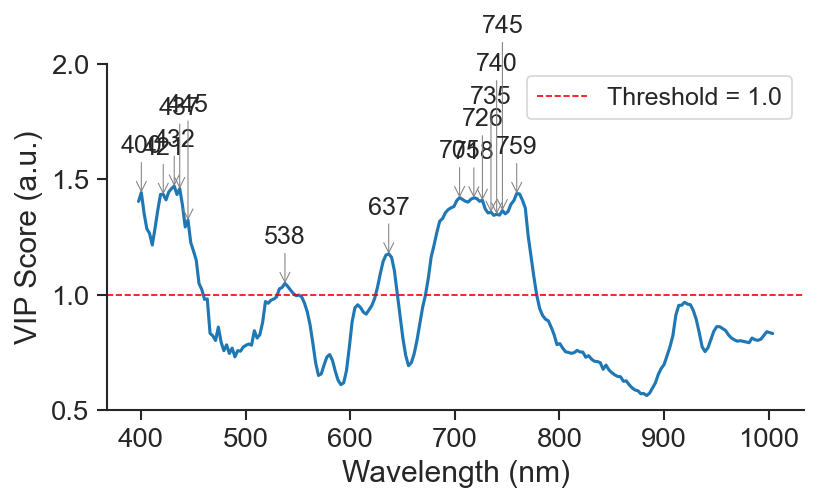

In [102]:
plt.figure(figsize=(6, 3))
sns.lineplot(data=df_vip, x="Wavelength", y="VIP Score",
             estimator=None, errorbar=None)
plt.xlabel("Wavelength (nm)")
plt.ylabel("VIP Score (a.u.)")
plt.axhline(y=1.0, color="red", linestyle="--", label="Threshold = 1.0", lw=0.8)
y_min, y_max = plt.ylim()
plt.yticks(np.arange(0.5, y_max + 0.5, step=0.5))
prev_x, offset = None, 0
for x in sorted(vip_peaks):
    score = df_vip.loc[df_vip["Wavelength"] == x, "VIP Score"].iloc[0]
    if prev_x is not None and abs(x - prev_x) < 10:
        offset += 1
    else:
        offset = 0
    prev_x = x
    plt.annotate(
        f"{int(round(x))}", xy=(x, score),
        xytext=(x, score + (y_max - y_min) * 0.15 * (offset + 1)),
        ha="center", va="bottom", fontsize=12,
        arrowprops=dict(arrowstyle="->", color="gray", lw=0.5,
                        shrinkA=0, shrinkB=0),
    )
plt.legend(fontsize=12)
plt.show()

#### Confusion Matrices

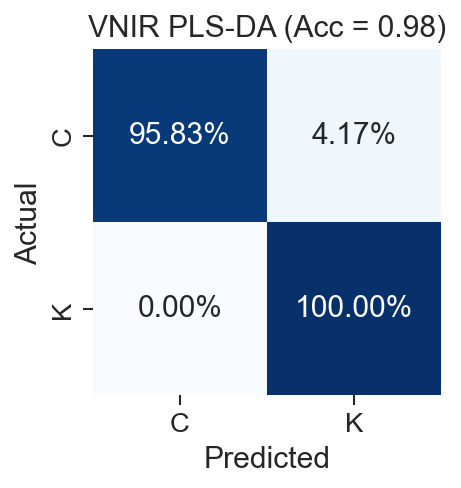

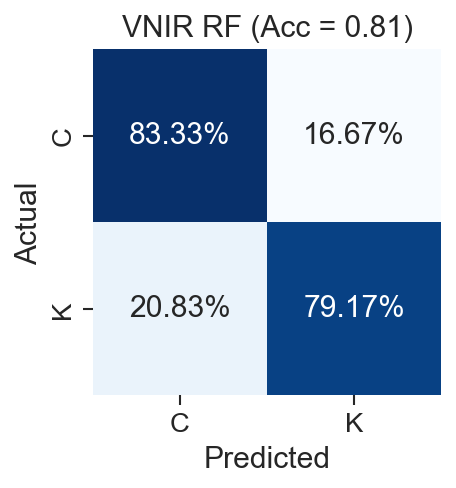

In [19]:
plot_confusion_matrix(
    result["target"]["y_true"], result["target"]["y_pred"],
    class_names=["C", "K"],
    title=f"VNIR PLS-DA (Acc = {result['metrics']['accuracy']:.2f})",
)
plot_confusion_matrix(
    rf_y_test, rf_y_pred,
    class_names=["C", "K"],
    title=f"VNIR RF (Acc = {rf_metrics['accuracy']:.2f})",
)

## 5. SWIR Analysis

### 5.1 Data Loading

In [20]:
df_swir, df_spectra_swir = load_and_prepare(SENSORS["SWIR"])
print(f"SWIR — {df_swir['Fish'].nunique()} samples, "
      f"{len(df_swir.columns) - 2} wavelengths, "
      f"{df_swir['Treatment'].nunique()} classes")
df_spectra_swir.head()

SWIR — 24 samples, 270 wavelengths, 2 classes


,Fish,Treatment,Wavelength,Intensity,Image
0,1,C,998.84,0.214580,1-C
1,1,C,1004.48,0.219941,1-C
2,1,C,1010.13,0.225789,1-C
3,1,C,1015.77,0.231892,1-C
4,1,C,1021.41,0.237882,1-C


### 5.2 Visualisation

#### All Samples

C:\Users\lalle\AppData\Local\Temp\ipykernel_22968\2793100728.py:2: UserWarning: 
The palette list has fewer values (10) than needed (48) and will cycle, which may produce an uninterpretable plot.
  sns.lineplot(


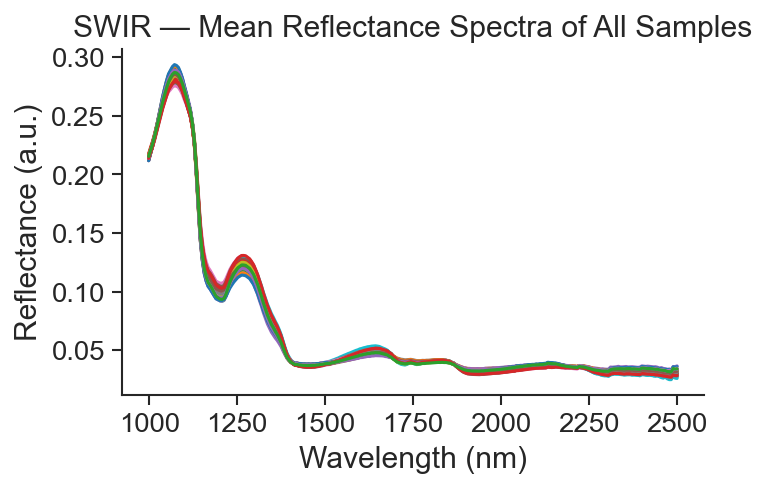

In [21]:
n_images_swir = df_spectra_swir["Image"].nunique()
sns.lineplot(
    data=df_spectra_swir, x="Wavelength", y="Intensity",
    hue="Image", units="Image",
    estimator=None, palette=sns.color_palette("tab10")[::-1],
    legend=False, errorbar=None,
)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Reflectance (a.u.)")
plt.title("SWIR — Mean Reflectance Spectra of All Samples")
plt.show()

#### Mean Spectral Reflectance per Treatment

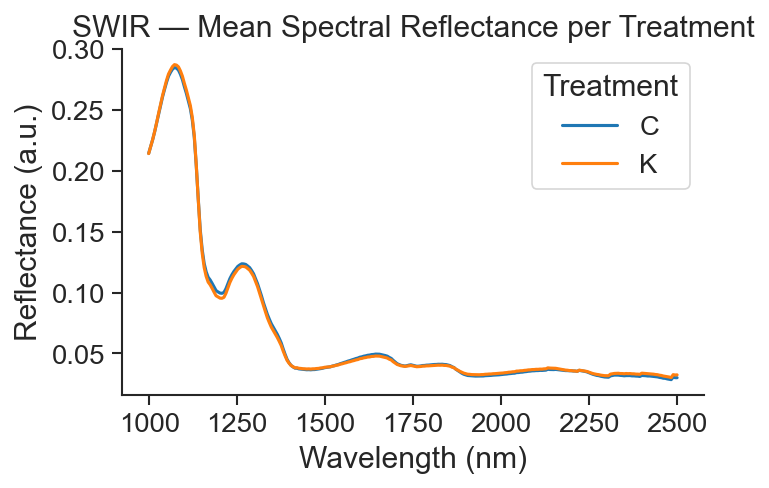

In [22]:
sns.lineplot(
    data=df_spectra_swir, x="Wavelength", y="Intensity",
    hue="Treatment", errorbar=None,
)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Reflectance (a.u.)")
plt.title("SWIR — Mean Spectral Reflectance per Treatment")
plt.legend(title="Treatment")
plt.show()

#### Adjusted Mean Spectral Reflectance

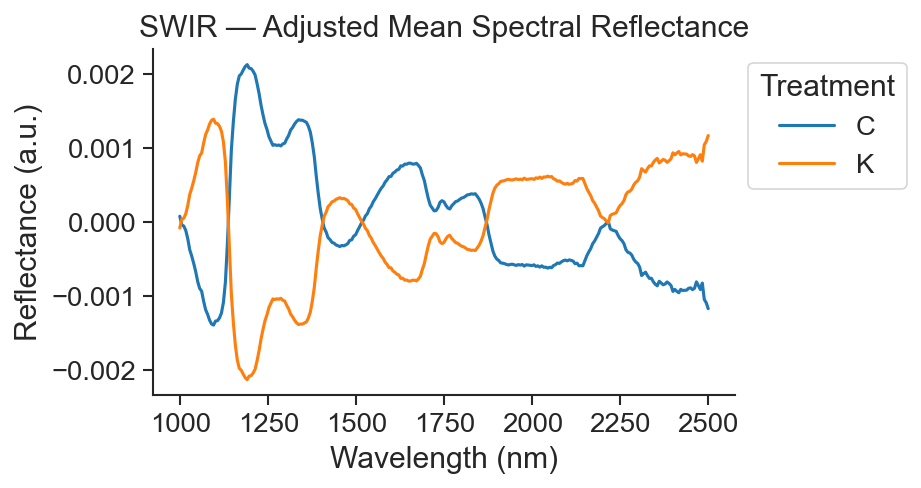

In [23]:
df_C_mean_swir = (df_spectra_swir[df_spectra_swir["Treatment"] == "C"]
                  .groupby("Wavelength")["Intensity"].mean().reset_index())
df_K_mean_swir = (df_spectra_swir[df_spectra_swir["Treatment"] == "K"]
                  .groupby("Wavelength")["Intensity"].mean().reset_index())

grand_mean_swir = (df_C_mean_swir["Intensity"] + df_K_mean_swir["Intensity"]) / 2
df_C_mean_swir["Adjusted"] = df_C_mean_swir["Intensity"] - grand_mean_swir
df_K_mean_swir["Adjusted"] = df_K_mean_swir["Intensity"] - grand_mean_swir

sns.lineplot(data=df_C_mean_swir, x="Wavelength", y="Adjusted", label="C", errorbar=None)
sns.lineplot(data=df_K_mean_swir, x="Wavelength", y="Adjusted", label="K", errorbar=None)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Reflectance (a.u.)")
plt.title("SWIR — Adjusted Mean Spectral Reflectance")
plt.legend(title="Treatment", bbox_to_anchor=(1, 1), loc="upper left")
plt.show()

### 5.3 Statistical Analysis

Welch's t-test (unequal-variance) is applied independently at each wavelength. Benjamini-Hochberg FDR correction controls the false discovery rate. Cohen's *d* is reported as a standardised effect size per wavelength.

In [24]:
results_df_swir = run_ttest_analysis(df_spectra_swir)

n_sig = results_df_swir["Significant"].sum()
n_total = len(results_df_swir)
print(f"SWIR — Significant wavelengths (FDR-adjusted p < 0.05): {n_sig} / {n_total}")
print(f"Cohen's d range: [{results_df_swir['cohens_d'].min():.3f}, {results_df_swir['cohens_d'].max():.3f}]")

SWIR — Significant wavelengths (FDR-adjusted p < 0.05): 212 / 270
Cohen's d range: [-2.466, 2.059]


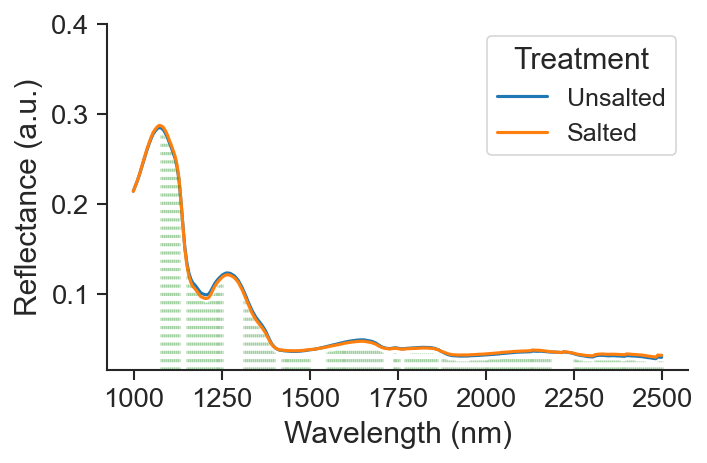

In [57]:
sns.lineplot(
    data=df_spectra_swir, x="Wavelength", y="Intensity",
    hue="Treatment", estimator=np.mean, errorbar=None,
)
plt.yticks(np.arange(0.1, 0.5, 0.1))
y_min, y_max = plt.ylim()
for _, row in results_df_swir[results_df_swir["Significant"]].iterrows():
    wl = row["Wavelength"]
    intensity = row["mean_intensity"]
    ymax_rel = (intensity - y_min) / (y_max - y_min)
    plt.axvline(x=wl, color="green", linestyle=":", alpha=0.2, ymax=ymax_rel - 0.015)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Reflectance (a.u.)")
# plt.title("SWIR — Significant Wavelengths (FDR-corrected)")
plt.legend(title="Treatment", labels=["Unsalted", "Salted"], fontsize=12)
plt.show()

### 5.4 Machine Learning Classification

PLS-DA and Random Forest with Leave-One-Group-Out (LOGO) cross-validation — each fish is held out for one fold.

In [26]:
X_swir, y_swir, groups_swir, wavelengths_swir = prepare_ml_data(df_swir)

# PLS-DA (Leave-One-Group-Out CV)
result_swir = pls_da_classification(X_swir, y_swir, groups=groups_swir,
                                    max_components=20, cv=5, scoring="accuracy")

--- PLS-DA Leave-One-Group-Out CV (24 folds) ---
n_components (mode): 4  (distribution: {3: 3, 5: 8, 6: 3, 4: 9, 7: 1})
  accuracy: 0.8958
  auc: 0.9740
  precision: 0.9130
  recall: 0.8750
  f1: 0.8936


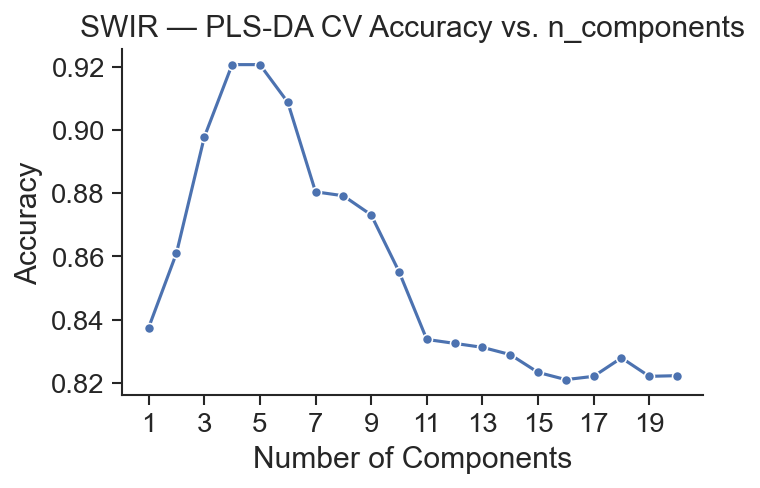

In [27]:
n_comp_swir = len(result_swir["mean_test_scores"])
sns.lineplot(
    x=range(1, n_comp_swir + 1), y=result_swir["mean_test_scores"],
    marker="o", linestyle="-", color="b",
)
plt.xlabel("Number of Components")
plt.xticks(np.arange(1, n_comp_swir + 1, step=2))
plt.ylabel("Accuracy")
plt.title("SWIR — PLS-DA CV Accuracy vs. n_components")
plt.show()

In [28]:
# Random Forest (Leave-One-Group-Out CV)
rf_swir, rf_y_test_swir, rf_y_pred_swir, rf_metrics_swir = random_forest_classification(
    X_swir, y_swir, groups=groups_swir, use_grid_search=True,
)

--- Random Forest Leave-One-Group-Out CV (24 folds) ---
  accuracy: 0.8542
  auc: 0.9193
  precision: 0.8696
  recall: 0.8333
  f1: 0.8511


### 5.5 Results & Interpretation

#### Feature Importance (Random Forest)

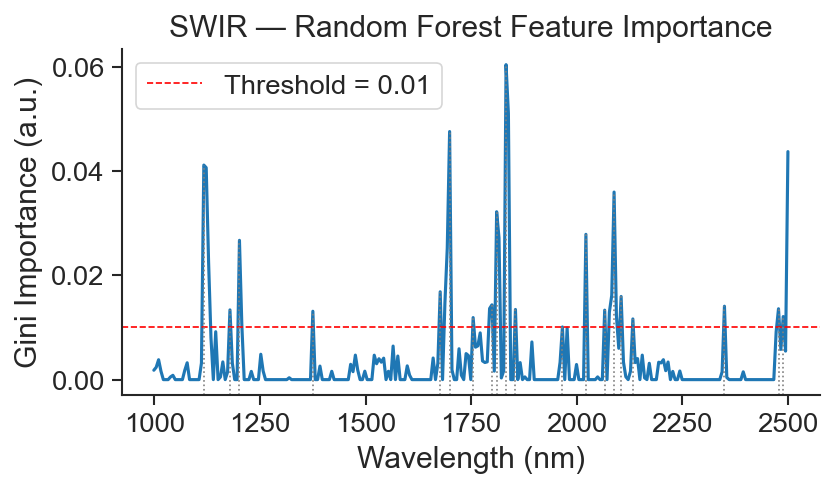

In [29]:
df_importance_swir = pd.DataFrame({
    "Wavelength": wavelengths_swir,
    "Importance": rf_swir.feature_importances_,
})

plt.figure(figsize=(6, 3))
sns.lineplot(data=df_importance_swir, x="Wavelength", y="Importance",
             estimator=None, errorbar=None)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Gini Importance (a.u.)")
y_min, y_max = plt.ylim()
plt.axhline(y=0.01, color="red", linestyle="--", label="Threshold = 0.01", lw=0.8)
biomarkers_swir = find_local_maxima(df_importance_swir, th=0.01)
for x in biomarkers_swir:
    score = df_importance_swir.loc[df_importance_swir["Wavelength"] == x, "Importance"].iloc[0]
    ymax_rel = (score - y_min) / (y_max - y_min)
    plt.axvline(x=x, ymax=ymax_rel, color="gray", linestyle=":", lw=0.8)
plt.legend()
plt.title("SWIR — Random Forest Feature Importance")
plt.show()

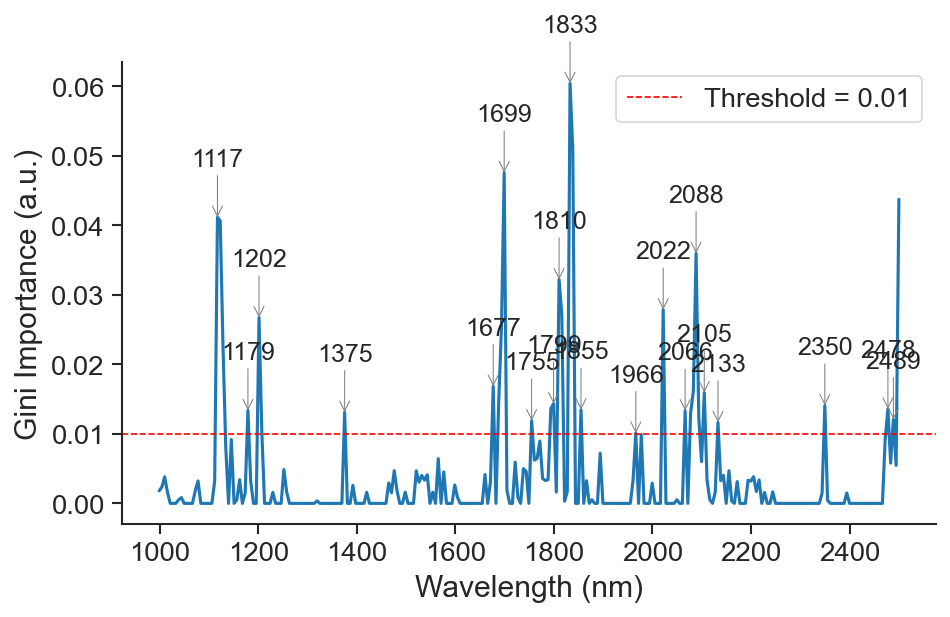

In [82]:
plt.figure(figsize=(7, 4))
sns.lineplot(data=df_importance_swir, x="Wavelength", y="Importance",
             estimator=None, errorbar=None)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Gini Importance (a.u.)")
plt.axhline(y=0.01, color="red", linestyle="--", label="Threshold = 0.01", lw=0.8)
y_min, y_max = plt.ylim()
prev_x, offset = None, 0
for x in sorted(biomarkers_swir):
    score = df_importance_swir.loc[df_importance_swir["Wavelength"] == x, "Importance"].iloc[0]
    if prev_x is not None and abs(x - prev_x) < 10:
        offset += 1
    else:
        offset = 0
    prev_x = x
    plt.annotate(
        f"{int(round(x))}", xy=(x, score),
        xytext=(x, score + (y_max - y_min) * 0.1 * (offset + 1)),
        ha="center", va="bottom", fontsize=12,
        arrowprops=dict(arrowstyle="->", color="gray", lw=0.5,
                        shrinkA=0, shrinkB=0),
    )
plt.legend()
plt.show()

#### VIP Scores (PLS-DA)

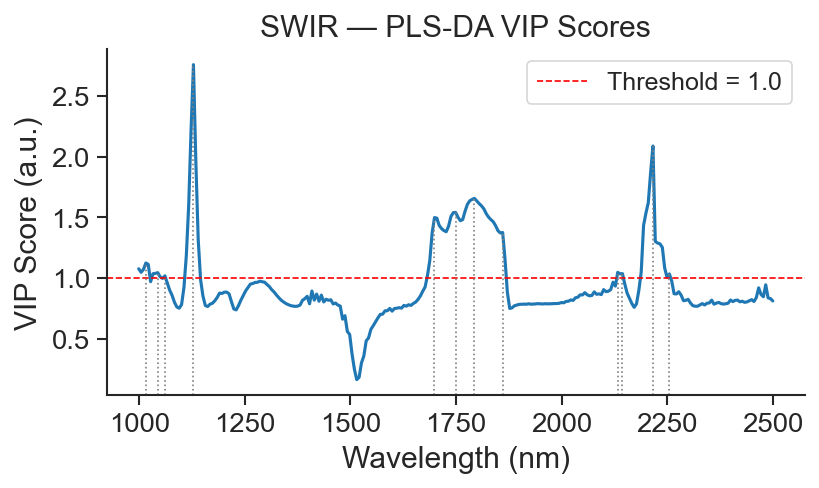

In [31]:
df_vip_swir = pd.DataFrame({
    "Wavelength": wavelengths_swir,
    "VIP Score": result_swir["vip"],
})

plt.figure(figsize=(6, 3))
sns.lineplot(data=df_vip_swir, x="Wavelength", y="VIP Score",
             estimator=None, errorbar=None)
plt.xlabel("Wavelength (nm)")
plt.ylabel("VIP Score (a.u.)")
plt.axhline(y=1.0, color="red", linestyle="--", label="Threshold = 1.0", lw=0.8)
vip_peaks_swir = find_local_maxima(df_vip_swir, th=1.0)
y_min, y_max = plt.ylim()
for x in vip_peaks_swir:
    score = df_vip_swir.loc[df_vip_swir["Wavelength"] == x, "VIP Score"].iloc[0]
    ymax_rel = (score - y_min) / (y_max - y_min)
    plt.axvline(x=x, ymax=ymax_rel, color="gray", linestyle=":", lw=0.8)
plt.legend(fontsize=12)
plt.title("SWIR — PLS-DA VIP Scores")
plt.show()

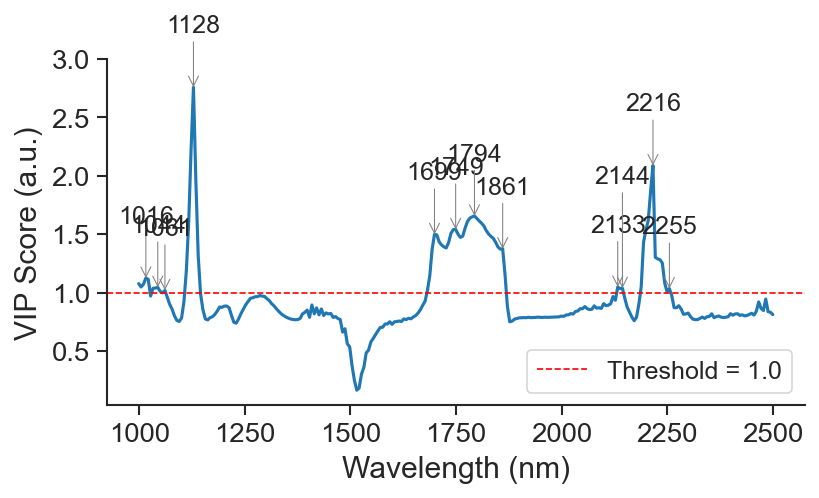

In [98]:
plt.figure(figsize=(6, 3))
sns.lineplot(data=df_vip_swir, x="Wavelength", y="VIP Score",
             estimator=None, errorbar=None)
plt.xlabel("Wavelength (nm)")
plt.ylabel("VIP Score (a.u.)")
plt.axhline(y=1.0, color="red", linestyle="--", label="Threshold = 1.0", lw=0.8)
y_min, y_max = plt.ylim()
plt.yticks(np.arange(0.5, y_max + 0.5, step=0.5))

prev_x, offset = None, 0
for x in sorted(vip_peaks_swir):
    score = df_vip_swir.loc[df_vip_swir["Wavelength"] == x, "VIP Score"].iloc[0]
    if prev_x is not None and abs(x - prev_x) < 16:
        offset += 1
    else:
        offset = 0
    prev_x = x
    plt.annotate(
        f"{int(round(x))}", xy=(x, score),
        xytext=(x, score + (y_max - y_min) * 0.15 * (offset + 1)),
        ha="center", va="bottom", fontsize=12,
        arrowprops=dict(arrowstyle="->", color="gray", lw=0.5,
                        shrinkA=0, shrinkB=0),
    )
plt.legend(fontsize=12)
plt.show()

#### Confusion Matrices

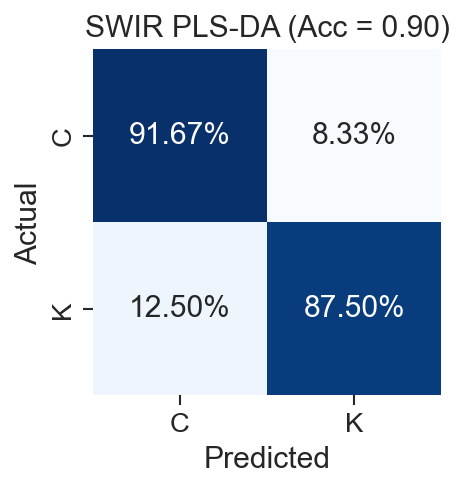

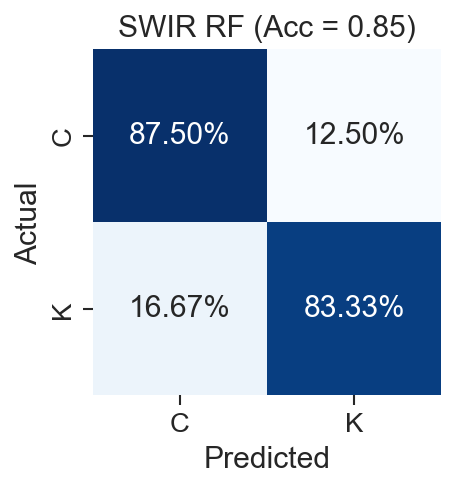

In [33]:
plot_confusion_matrix(
    result_swir["target"]["y_true"], result_swir["target"]["y_pred"],
    class_names=["C", "K"],
    title=f"SWIR PLS-DA (Acc = {result_swir['metrics']['accuracy']:.2f})",
)
plot_confusion_matrix(
    rf_y_test_swir, rf_y_pred_swir,
    class_names=["C", "K"],
    title=f"SWIR RF (Acc = {rf_metrics_swir['accuracy']:.2f})",
)

## 6. Cross-Sensor Comparison

Summary of predictive performance (pooled LOGO CV), side-by-side VIP spectra, and four-panel confusion matrices for VNIR and SWIR.

In [34]:
comparison_data = {
    "Sensor":        ["VNIR",                                       "SWIR"],
    "PLS-DA n_comp": [result["n_components"],                       result_swir["n_components"]],
    "PLS-DA Acc":    [f"{result['metrics']['accuracy']:.3f}",       f"{result_swir['metrics']['accuracy']:.3f}"],
    "PLS-DA AUC":    [f"{result['metrics']['auc']:.3f}",            f"{result_swir['metrics']['auc']:.3f}"],
    "PLS-DA F1":     [f"{result['metrics']['f1']:.3f}",             f"{result_swir['metrics']['f1']:.3f}"],
    "RF Acc":        [f"{rf_metrics['accuracy']:.3f}",              f"{rf_metrics_swir['accuracy']:.3f}"],
    "RF AUC":        [f"{rf_metrics['auc']:.3f}",                   f"{rf_metrics_swir['auc']:.3f}"],
    "RF F1":         [f"{rf_metrics['f1']:.3f}",                    f"{rf_metrics_swir['f1']:.3f}"],
}

df_comparison = pd.DataFrame(comparison_data).set_index("Sensor")
print("=== Cross-Sensor Classification Performance (LOGO CV) ===")
df_comparison

=== Cross-Sensor Classification Performance (LOGO CV) ===


,PLS-DA n_comp,PLS-DA Acc,PLS-DA AUC,PLS-DA F1,RF Acc,RF AUC,RF F1
Sensor,,,,,,,
VNIR,13,0.979,1.000,0.980,0.812,0.880,0.809
SWIR,4,0.896,0.974,0.894,0.854,0.919,0.851


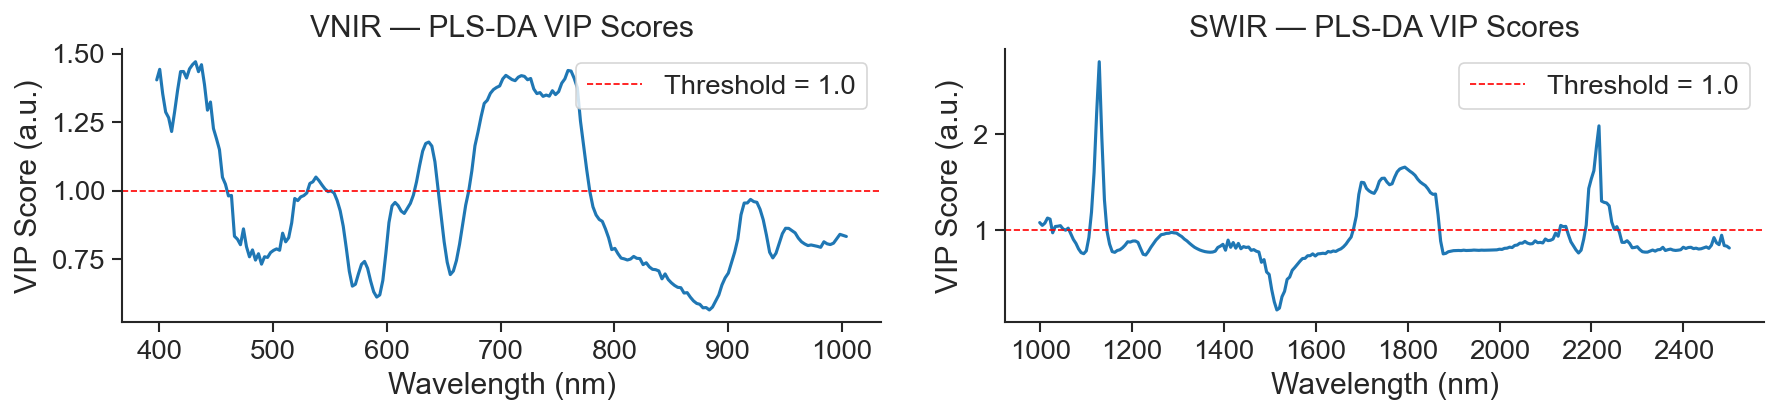

In [35]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3))

sns.lineplot(data=df_vip, x="Wavelength", y="VIP Score",
             estimator=None, errorbar=None, ax=ax1)
ax1.axhline(y=1.0, color="red", linestyle="--", lw=0.8, label="Threshold = 1.0")
ax1.set_xlabel("Wavelength (nm)")
ax1.set_ylabel("VIP Score (a.u.)")
ax1.set_title("VNIR — PLS-DA VIP Scores")
ax1.legend()

sns.lineplot(data=df_vip_swir, x="Wavelength", y="VIP Score",
             estimator=None, errorbar=None, ax=ax2)
ax2.axhline(y=1.0, color="red", linestyle="--", lw=0.8, label="Threshold = 1.0")
ax2.set_xlabel("Wavelength (nm)")
ax2.set_ylabel("VIP Score (a.u.)")
ax2.set_title("SWIR — PLS-DA VIP Scores")
ax2.legend()

plt.tight_layout()
plt.show()

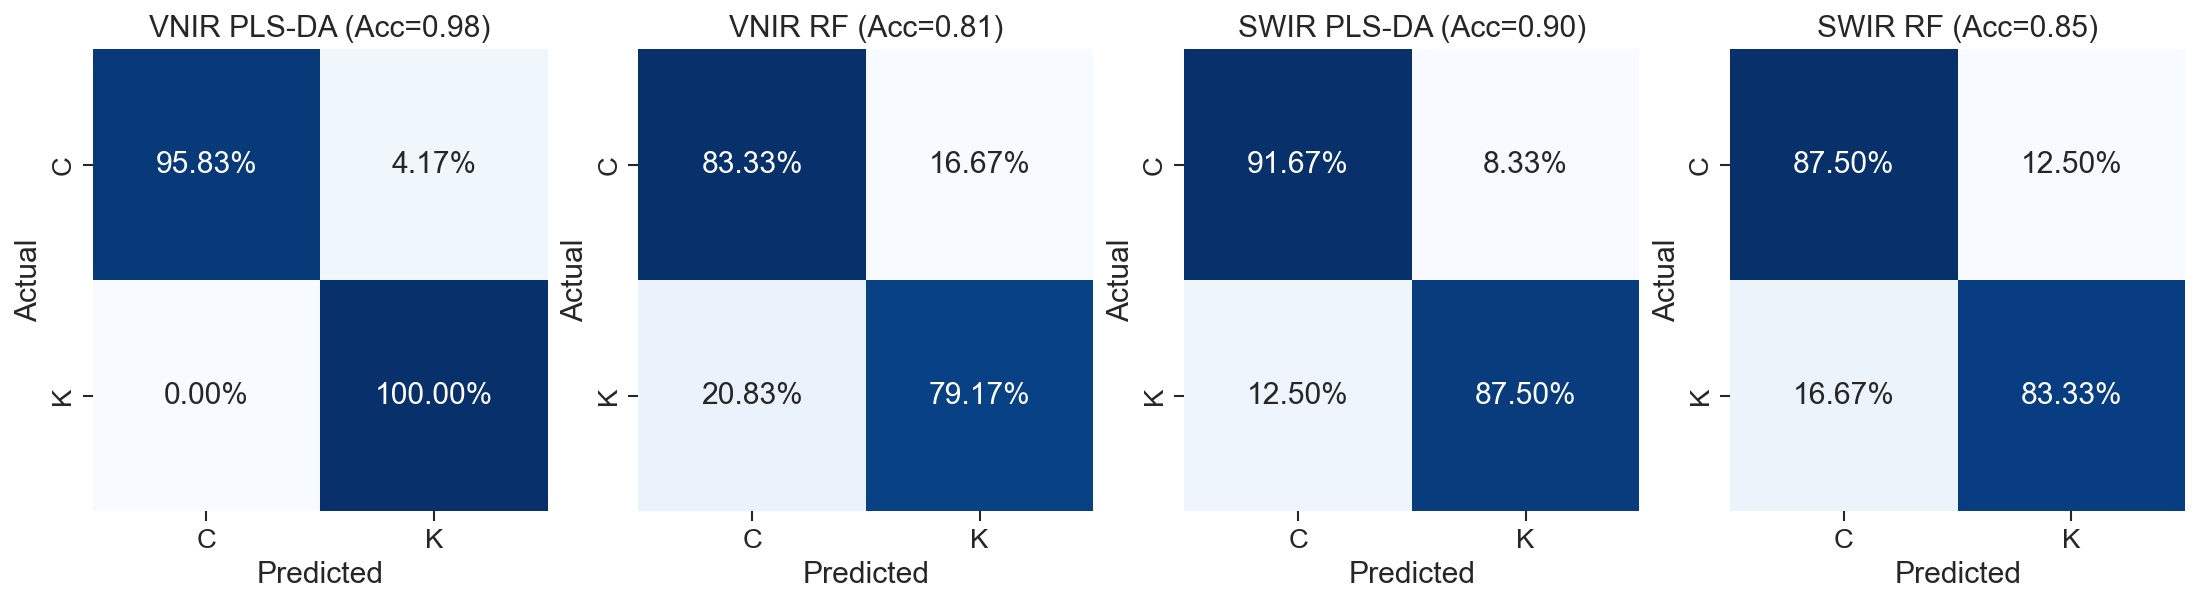

<Figure size 750x450 with 0 Axes>

In [36]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

plot_confusion_matrix(
    result["target"]["y_true"], result["target"]["y_pred"],
    class_names=["C", "K"],
    title=f"VNIR PLS-DA (Acc={result['metrics']['accuracy']:.2f})",
    ax=axes[0],
)
plot_confusion_matrix(
    rf_y_test, rf_y_pred,
    class_names=["C", "K"],
    title=f"VNIR RF (Acc={rf_metrics['accuracy']:.2f})",
    ax=axes[1],
)
plot_confusion_matrix(
    result_swir["target"]["y_true"], result_swir["target"]["y_pred"],
    class_names=["C", "K"],
    title=f"SWIR PLS-DA (Acc={result_swir['metrics']['accuracy']:.2f})",
    ax=axes[2],
)
plot_confusion_matrix(
    rf_y_test_swir, rf_y_pred_swir,
    class_names=["C", "K"],
    title=f"SWIR RF (Acc={rf_metrics_swir['accuracy']:.2f})",
    ax=axes[3],
)
plt.tight_layout()
plt.show()